In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

sns.set_style("whitegrid")

In [2]:
gxt_test = pd.read_excel('Podatki doktorski študij seminar.xlsx', sheet_name='vecstopenjski_test') 
ss_test = pd.read_excel('Podatki doktorski študij seminar.xlsx', sheet_name='neprekinjen_test')

gxt_test_columns = ['test', 'V', 'Vo2', 'Ve', 'HR', 'La', 'GLU']
var_columns = ['Vo2', 'Ve', 'HR', 'La', 'GLU', 'HR_Vo2_ratio', 'Ve_Vo2_ratio']
ss_test_columns = gxt_test_columns.copy()
ss_test_columns.insert(2, 't')
gxt_test.columns = gxt_test_columns
ss_test.columns = ss_test_columns

# Samo v primeru, kjer želimo gledat razmerja
gxt_test = gxt_test.assign(
    #HR_Vo2_ratio = lambda x: x.HR/x.Vo2,
    Ve_Vo2_ratio = lambda x: x.Ve/x.Vo2,
    #log_La_ratio = lambda x: np.log10(x.La),
    #log_Vo2_ratio = lambda x: np.log10(x.Vo2)
)
gxt_test.head()

,test,V,Vo2,Ve,HR,La,GLU,Ve_Vo2_ratio
0,1,6,1.619,21,92,2.5,4.9,12.970970
1,1,8,2.148,54,109,1.2,4.1,25.139665
2,1,10,2.693,73,130,1.5,4.0,27.107315
3,1,12,3.386,95,153,3.2,3.8,28.056704
4,1,14,3.762,113,167,7.4,4.2,30.037214


In [3]:
ss_test = ss_test.assign(
    #HR_Vo2_ratio = lambda x: x.HR/x.Vo2,
    Ve_Vo2_ratio = lambda x: x.Ve/x.Vo2,
    #log_La_ratio = lambda x: np.log10(x.La),
    #log_Vo2_ratio = lambda x: np.log10(x.Vo2Ž)
)
ss_test = ss_test.fillna(0) # napolnimo vrednosti za prvi test, ki dejansko ne obstaja z ničlami samo zato, da je lažje prikazati podatke.
ss_test.head()

,test,V,t,Vo2,Ve,HR,La,GLU,Ve_Vo2_ratio
0,2,10,5,2.526,63,112,1.4,5.8,24.940618
1,2,10,20,2.551,65,130,1.2,4.4,25.480204
2,2,10,40,2.569,66,133,1.1,4.9,25.690930
3,2,10,60,2.586,68,145,1.4,4.9,26.295437
4,3,12,5,3.692,102,159,6.0,5.1,27.627302


In [4]:
def baseline_plus(speed, lactate, offset=0, obla=False, obla_val=4.0, search_min=8):
    speed, lactate = speed.to_numpy(), lactate.to_numpy()
    f = interp1d(speed, lactate, kind='quadratic', bounds_error=False, fill_value='extrapolate')
    interp_v = np.arange(search_min, 14.1, 0.1)
    interp_la = f(interp_v)
    # za baseline vzemi drugo hitrost
    baseline_offset = obla_val if obla else lactate[1] + offset
    sorted_v = interp_v[np.argsort(np.abs(interp_la-baseline_offset))]
    return sorted_v[0], baseline_offset
    
def dmax_method(speed, lactate, polynomial=False, lt1=False):
    speed, lactate = speed.to_numpy(), lactate.to_numpy()
    if polynomial:
        p = np.polyfit(speed, lactate, 3)
        poly = np.poly1d(p)
        lactate = poly(speed)
    
    midpoint = len(speed) // 2
    if lt1:
        speed = speed[:midpoint + 2]
        lactate = lactate[:midpoint + 2]
    else:
        speed = speed[midpoint - 1:]
        lactate = lactate[midpoint - 1:]

    line = np.linspace(0, 1, 30)
    x = [speed[0], speed[-1]]
    y = [lactate[0], lactate[-1]]
    dist=[]
    
    for i in range(len(speed)):
        # nariši linijo med začetno in končno točko na grafu hitrost vs. laktat
        x0, y0 = speed[i], lactate[i]
        # najdi točko z navečjo razdaljo do polinomsko funkcijo
        num = abs((y[1] - y[0])*x0 - (x[1] - x[0])*y0 + x[1]*y[0] - x[0]*y[1])
        den = np.sqrt((y[1] - y[0])**2 + (x[1] - x[0])**2)
        dist.append(num / den)
    idx = np.argmax(dist)
    return speed[idx]

## Določanje domen intenzivnosti teka glede na notranje kazalnike (koncentracija laktata v krvi med obremenitvenim testom)

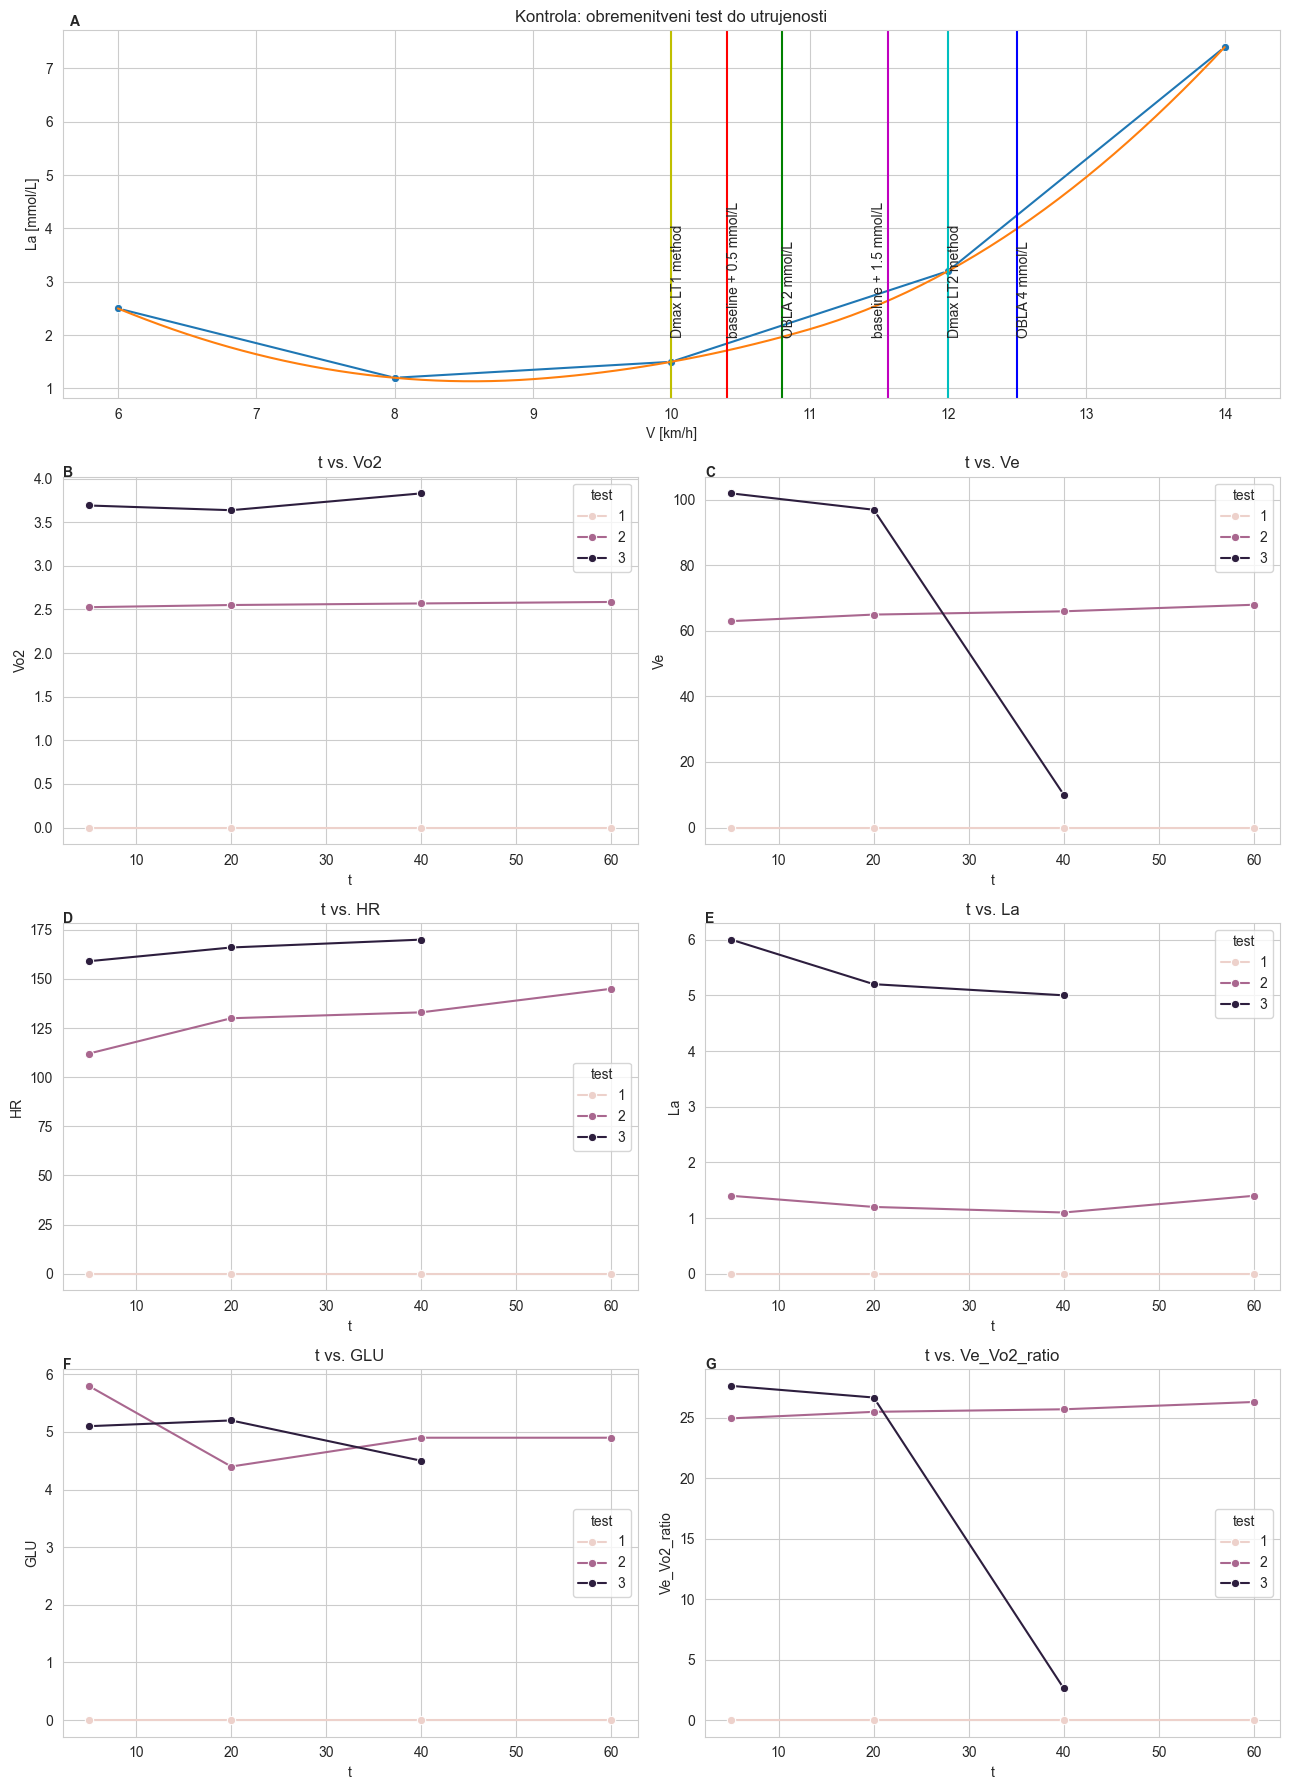

In [8]:
fig = plt.figure(figsize=(13, 18));
gs = fig.add_gridspec(4,2)
ax0 = fig.add_subplot(gs[0,:])

vel, lac = gxt_test[gxt_test.test==1]['V'], gxt_test[gxt_test.test==1]['La'];
sns.lineplot(data=gxt_test[gxt_test.test==1], x='V', y='La', marker='o', ax=ax0);
ax0.set_title('Kontrola: obremenitveni test do utrujenosti')
ax0.set_xlabel('V [km/h]');
ax0.set_ylabel('La [mmol/L]');
# nariši interpolirano krivuljo
interp_data = interp1d(vel, lac, kind='quadratic', bounds_error=False, fill_value='extrapolate')
interp_v = np.arange(6, 14.1, 0.1)
interp_la = interp_data(interp_v)
int_df = np.vstack((interp_v, interp_la));
interp_df = pd.DataFrame(int_df.T, columns=['V', 'La'])
sns.lineplot(data=interp_df, x='V', y='La', ax=ax0);
# izračunaj  in vriši točke LT1 --> baseline + 0.5 mmol/L offset, OBLA 2 
text_y = 2
ax0.axvline(baseline_plus(vel, lac, offset=0.5)[0], color='r')
ax0.text(baseline_plus(vel, lac, offset=0.5)[0], text_y, 'baseline + 0.5 mmol/L', rotation=90);

ax0.axvline(baseline_plus(vel, lac, obla=True, obla_val=2)[0], color='g')
ax0.text(baseline_plus(vel, lac, obla=True, obla_val=2)[0], text_y, 'OBLA 2 mmol/L', rotation=90);

ax0.axvline(dmax_method(vel, lac, polynomial=True, lt1=True), color='y');
ax0.text(dmax_method(vel, lac, polynomial=True, lt1=True), text_y, 'Dmax LT1 method', rotation=90);

# izračunaj in vriši točke LT2 --> OBLA 4, 
ax0.axvline(baseline_plus(vel, lac, obla=True, obla_val=4)[0], color='b')
ax0.text(baseline_plus(vel, lac, obla=True, obla_val=4)[0], text_y, 'OBLA 4 mmol/L', rotation=90);

ax0.axvline(dmax_method(vel, lac, polynomial=True, lt1=False), color='c');
ax0.text(dmax_method(vel, lac, polynomial=True, lt1=False), text_y, 'Dmax LT2 method', rotation=90);

ax0.axvline(baseline_plus(vel, lac, offset=1.5)[0]-0.03, color='m')
ax0.text(baseline_plus(vel, lac, offset=1.5)[0]-0.15, text_y, 'baseline + 1.5 mmol/L', rotation=90);
ax0.text(ax0.get_xlim()[0]*1.01, ax0.get_ylim()[1]*1.01, 'A', fontweight='bold')

# LT1 plots
params = gxt_test.columns[2:].to_numpy().reshape(3,2)
annot = [['B', 'C'],['D', 'E'],['F', 'G']]
for r in range(1, 4):
    for c in range(2):
        
        ax = fig.add_subplot(gs[r,c])
        sns.lineplot(data=ss_test, x='t', y=params[r-1,c], hue='test', ax=ax, marker='o');
        ax.set_title(f't vs. {params[r-1,c]}');
        ax.text(ax.get_xlim()[0], ax.get_ylim()[1], annot[r-1][c], fontweight='bold')

plt.tight_layout()
filename = 'slika_1.png'
fig.savefig(filename, format="png", dpi=1200, bbox_inches="tight")
plt.show()

**Komentar:** S pomočjo kontrolnega obremenitvenega testa smo določili pragove intenzivnosti, za kar smo uporabili različne izračune prvega in drugega laktatnega praga (LT1 in LT2). Uporabili smo 6 različnih načinov izračuna pragov, rezultati katerih so prikazani na grafu A. Ker je koncentracija laktata pri prvi stopnji višja, kot pri drugi stopnji smo za bazno vrednost vzeli koncentracijo laktata pri hitrosti 8km/h. Za izračun LT1 smo uporabili metodo Dmax, prilagojeno za izračun LT1, OBLA 2 in povečanje nad bazno vrednost za 0.5 mmol/L. Za izračun LT2 smo uporabili metodi OBLA 4 in povečanje nad bazno vrednost za 1.5mmol/L in metodo Dmax. Iz rezultatov lahko vidimo, da se izračuni zaradi majhnega števila meritev precej razlikujejo med seboj. Tudi izbira bazne vrednosti koncentracije laktata pri hitrosti 8 km/h pomembno vpliva na rezultat določenih algoritmov.
#### Zmerna intenzivnost
Iz grafa **A** je razvidno, da je na podlagi uporabljenih izračunov hitrost pri kateri je merjenec v *zmerni domeni intenzivnosti telesne aktivnosti 10 km/h* oziroma malo nad to hitrostjo. To lahko potrdimo s preučitvijo krivulj drugega testa na grafih **B, C, D in E**, ki prikazujejo privzem kisika, ventilacijo, frekvenco srčnega utripa in koncentracijo laktata v krvi pri teku s konstantno hitrostjo 10 km/h v odvisnosti od časa teka. Povprečne vrednosti in njihove standardne deviacije si sledijo (avg, std):
+ Vo2: (2.56, 0.02) L/min
+ Ve: (65.5, 1.8) L/min
+ HR: (130, 11.8) 1/min
+ La: (1.28, 0.13) mmol/L
  
Glede na literaturo (Jamnick et al. 2022) spadajo te vrednosti v zmerno domeno intenzivnosti telesne aktivnosti. 
#### Težja intenzivnost
Iz grafa **A** je razvidno, da lahko hitrost pri LT2 in s tem območje *domene težje intenzivnosti telesne aktivnosti določimo v okolico 12 km/h*. Tudi to trditev lahko potrdimo s preučitvijo krivulj, tokrat tretjega testa na grafih **B, C, D in E**, ki prikazujejo privzem kisika, ventilacijo, frekvenco srčnega utripa in koncentracijo laktata v krvi pri teku s konstantno hitrostjo 12 km/h v odvisnosti od časa teka. Povprečne vrednosti in njihove standardne deviacije med testom imajo naslednje vrednosti:
+ Vo2: (3.72, 0.08) L/min
+ Ve: (69.7, 42.2) L/min
+ HR: (165, 4.5) 1/min
+ La: (5.4, 2.2) mmol/L

Merjenec testa pri 12 km/h ni zmogel dokončati. Preteči mu je uspelo 40 minut od 60 minutnega testa, kar glede na izmerjene vrednosti ni presenetljivo. Če upoštevamo njegov maksimalni srčni utrip z uporabo klasične enačbe: HR_max = 220 - starost, dobimo maksimalni srčni utrip 180, torej je večino testa opravil nad 90% njegovega maksimalnega srčnega utripa. Tudi koncentracija laktata med celotnim testom ni padla pod 5 mmol/L. Iz krivulje 3 lahko vidimo, da se po začetnem dvigu koncentracije laktata vzpostavi ravnotežje in se koncentracija laktata tekom testa postopoma znižuje do prekinitve testa zaradi nezmožnosti nadaljevanja. *(kaj lahko sklepamo iz tega? aerobni procesi potrebujejo nekaj časa, da začnejo delovati v smislu generiranja ATP molekul, zato v začetnem stanju, ko pretežno delujeta fosfagenski sistem in glikoliza koncentracija laktata naraste, saj ga noben od teh dveh sistemov ne porablja v dovoljšnji meri. Šele ko aerobni procesi 'zalaufajo' se vzpostavi ravnovesno stanje, ki koncentracijo laktata počasi znižajo)*. Kinetika privzema kisika je prehitra, da bi jo sploh lahko zaznali. Po prvih petih minutah teka pri 12 km/h se že vzpostavi stacionarno stanje, ki se ustali pri vrednostih okoli 3.7 L/min.

## Potek kazalnikov v odvisnosti od različnih pogojev testa obremenitve do utrujenosti

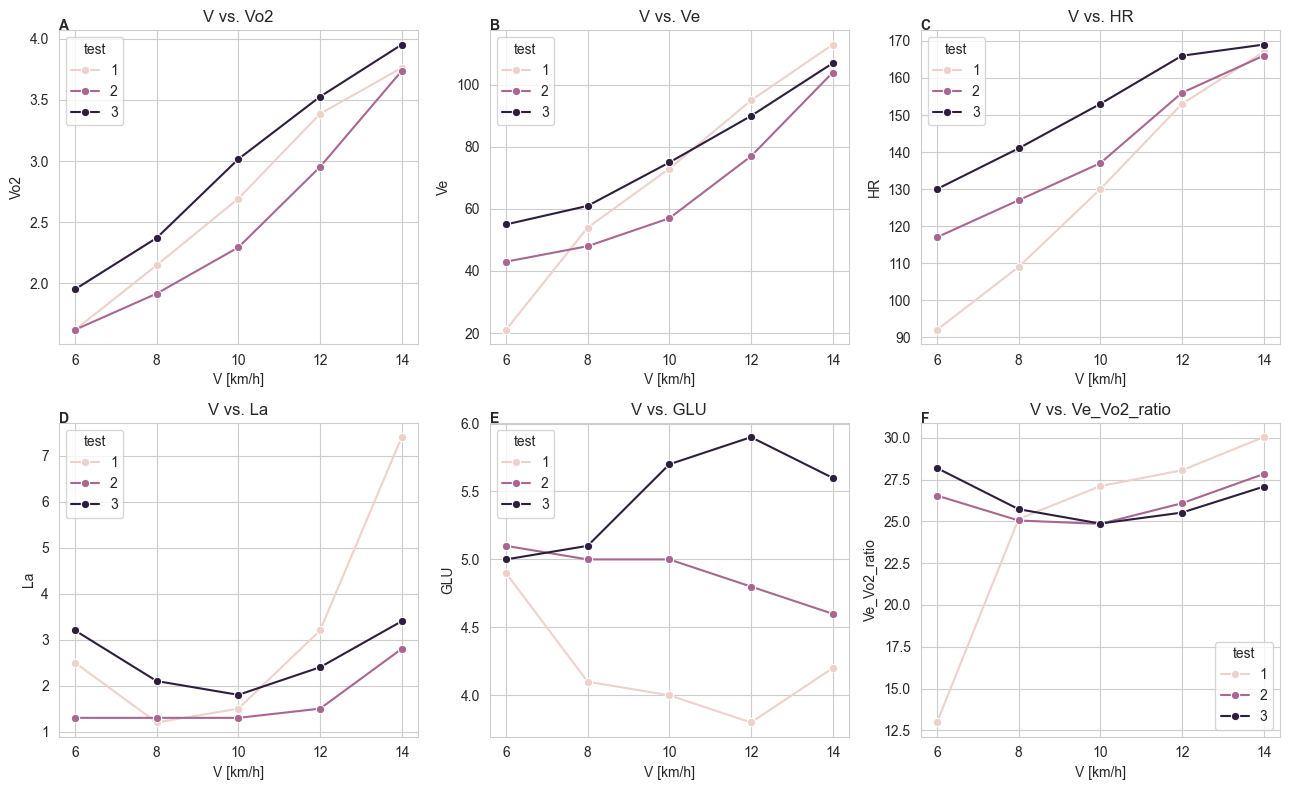

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
params = gxt_test.columns[2:]
annot = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
axes = axes.flatten()

for idx, m in enumerate(params):
    sns.lineplot(data=gxt_test, x='V', y=m, ax=axes[idx], hue='test', marker='o');
    axes[idx].set_title(f'V vs. {m}');
    axes[idx].set_xlabel('V [km/h]');
    axes[idx].text(axes[idx].get_xlim()[0], axes[idx].get_ylim()[1], annot[idx], fontweight='bold')

plt.tight_layout()
fig.savefig('slika2.png',format='png', dpi=1200)
plt.show()

### Tabela 1 razlike med odzivi merjenca ob opravljanju posameznega obremenitvenega testa

In [23]:
mass_kg = 76
gxt_test = gxt_test.copy()
gxt_test["RE_VO2_ml_kg_km"] = (gxt_test["Vo2"] * 1000 / mass_kg) / gxt_test["V"] * 60
gxt_test["VE_L_km"] = (gxt_test["Ve"]) / gxt_test["V"] * 60

# peak values
peak_values = gxt_test[['test', 'Vo2', 'Ve', 'HR', 'La']].groupby('test').max().T
peak_values = peak_values.rename(index={
    "Vo2": "Peak_VO2_L_min",
    "Ve":  "Peak_VE_L_min",
    "HR":  "Peak_HR_bpm",
    "La":  "Peak_La_mmol_L"
})

# mean values from 6 to 12 km/h
mean_subset = gxt_test[gxt_test.V <= 12]

mean_values = mean_subset[['test', 'Vo2', 'Ve', 'HR', 'La', 'Ve_Vo2_ratio']].groupby('test').mean().T
mean_values = mean_values.rename(index={
    "Vo2": "Mean_VO2_L_min_6_12",
    "Ve":  "Mean_VE_L_min_6_12",
    'HR':  'Mean_HR_bpm_6_12',
    "La":  "Mean_La_mmol_L_6_12",
    "Ve_Vo2_ratio": "Mean_VE_VO2_ratio_6_12"
})

# economy mean
economy_mean = mean_subset.groupby("test")[["RE_VO2_ml_kg_km", "VE_L_km"]].mean().T
economy_mean = economy_mean.rename(index={
    "RE_VO2_ml_kg_km": "Mean_RE_VO2_ml_kg_km_6_12",
    "VE_L_km": "Mean_VE_L_km_6_12"
    
})# hitrost pri obla 2 in 4 mmol/l
v_obla_2, v_obla_4 = [], []
for i in range(3):
    vel = gxt_test[gxt_test.test == i+1]['V']
    lac = gxt_test[gxt_test.test == i+1]['La']
    v_obla_2.append(baseline_plus(vel, lac, obla=True, obla_val=2, search_min=10)[0])
    v_obla_4.append(baseline_plus(vel, lac, obla=True, obla_val=4)[0])
v_obla_4[1:]=[np.nan,np.nan]

obla_df = pd.DataFrame(
    {"test": [1, 2, 3], "v_obla_2_km_h": v_obla_2, "v_obla_4_km_h": v_obla_4}
).set_index("test").T
obla_df = obla_df.rename(index={
    "v_obla_2_km_h": "v@2mmol_km_h",
    "v_obla_4_km_h": "v@4mmol_km_h"
})
#auc values
auc_vars = ['Vo2', 'Ve', 'HR', 'La']
auc_df = (
    gxt_test.sort_values('V')
      .groupby('test')
      .apply(lambda g: g[auc_vars].apply(lambda y: np.trapz(y, g['V'])), include_groups=False)
).T

auc_df = auc_df.rename(index={
    "Vo2": "AUC_VO2_(L_min·km_h)",
    "Ve":  "AUC_VE_(L_min·km_h)",
    "HR":  "AUC_HR_(bpm·km_h)",
    "La":  "AUC_La_(mmol_L·km_h)"
})

summary_df = pd.concat(
    [peak_values, mean_values, economy_mean, obla_df, auc_df],
    axis=0
).round(2)

summary_df.columns = [f"Obremenitveni test {int(c)}" for c in summary_df.columns]

summary_df.to_excel('Tabela_1.xlsx', index=True)
display(summary_df)

,Obremenitveni test 1,Obremenitveni test 2,Obremenitveni test 3
Peak_VO2_L_min,3.76,3.74,3.95
Peak_VE_L_min,113.00,104.00,107.00
Peak_HR_bpm,167.00,166.00,169.00
Peak_La_mmol_L,7.40,2.80,3.40
Mean_VO2_L_min_6_12,2.46,2.20,2.72
Mean_VE_L_min_6_12,60.75,56.25,70.25
Mean_HR_bpm_6_12,121.00,134.25,147.50
Mean_La_mmol_L_6_12,2.10,1.35,2.38
Mean_VE_VO2_ratio_6_12,23.32,25.63,26.08
Mean_RE_VO2_ml_kg_km_6_12,215.09,194.39,240.19


### Tabela 2 hitrost ter minimum in maximum fizioloških kazalnikov
Tabela prikazuje kakšna je bila minimalna in maksimalna vrednost kazalnika in pri kateri hitrosti je bila dosežena.

In [25]:
vars_ = ["Vo2", "Ve", "HR", "La", "GLU"]
stats = ["min", "V_at_min", "max", "V_at_max"]

def summarize_one_test(g):
    out = {}
    for m in vars_:
        idx_min = g[m].idxmin()
        idx_max = g[m].idxmax()
        out[(m, "min")] = g.loc[idx_min, m]
        out[(m, "V_at_min")] = g.loc[idx_min, "V"]
        out[(m, "max")] = g.loc[idx_max, m]
        out[(m, "V_at_max")] = g.loc[idx_max, "V"]
    return pd.Series(out)

wide = (
    gxt_test
    .groupby("test", sort=True, group_keys=False)
    .apply(summarize_one_test, include_groups=False)
)

wide = wide.reindex(columns=pd.MultiIndex.from_product([vars_, stats]))

def style_every_nth_col(df, every=4, decimals=2, line_px=2):
    n = df.shape[1]
    # 0-based column positions where we draw the right border:
    # after 4th col => index 3, then 7, 11, ...
    boundary_cols = list(range(every - 1, n, every))

    styles = []
    for j in boundary_cols:
        border = f"border-right: {line_px}px solid black;"
        styles += [
            {"selector": f"td.col{j}", "props": border},
            {"selector": f"th.col_heading.level0.col{j}", "props": border},
            {"selector": f"th.col_heading.level1.col{j}", "props": border},
        ]

    return (
        df.style
          .format(f"{{:.{decimals}f}}")     # two decimals everywhere
          .set_table_styles(styles, overwrite=False)
    )

styled = style_every_nth_col(wide, every=4, decimals=2, line_px=2)
styled

### Tabela 3 razlike med kontrolo in 1. ter 2. obremenitvenim testom
Tabela prikazuje razliko med kontrolno vrednostjo in vrednostjo posameznega fiziološkega kazalnika za vsako stopnjo obremenitvenega testa. 

In [26]:
vars_ = ["Vo2", "Ve", "HR", "La", "GLU"]

ctrl = (
    gxt_test[gxt_test["test"] == 1]
    .set_index("V")[vars_]
    .sort_index()
)

t2 = (
    gxt_test[gxt_test["test"] == 2]
    .set_index("V")[vars_]
    .sort_index()
)

t3 = (
    gxt_test[gxt_test["test"] == 3]
    .set_index("V")[vars_]
    .sort_index()
)

# Differences at each speed (index = V)
d21 = t2.sub(ctrl, fill_value=pd.NA)   # test2 - control
d31 = t3.sub(ctrl, fill_value=pd.NA)   # test3 - control

# Put into one table with a 2-level header: (comparison, variable)
diff_table = pd.concat({"Δ(2-1)": d21, "Δ(3-1)": d31}, axis=1)

diff_table.to_excel('tabela_2.xlsx', index=True)

styled_diff = style_every_nth_col(diff_table, every=5, decimals=2, line_px=2)
styled_diff

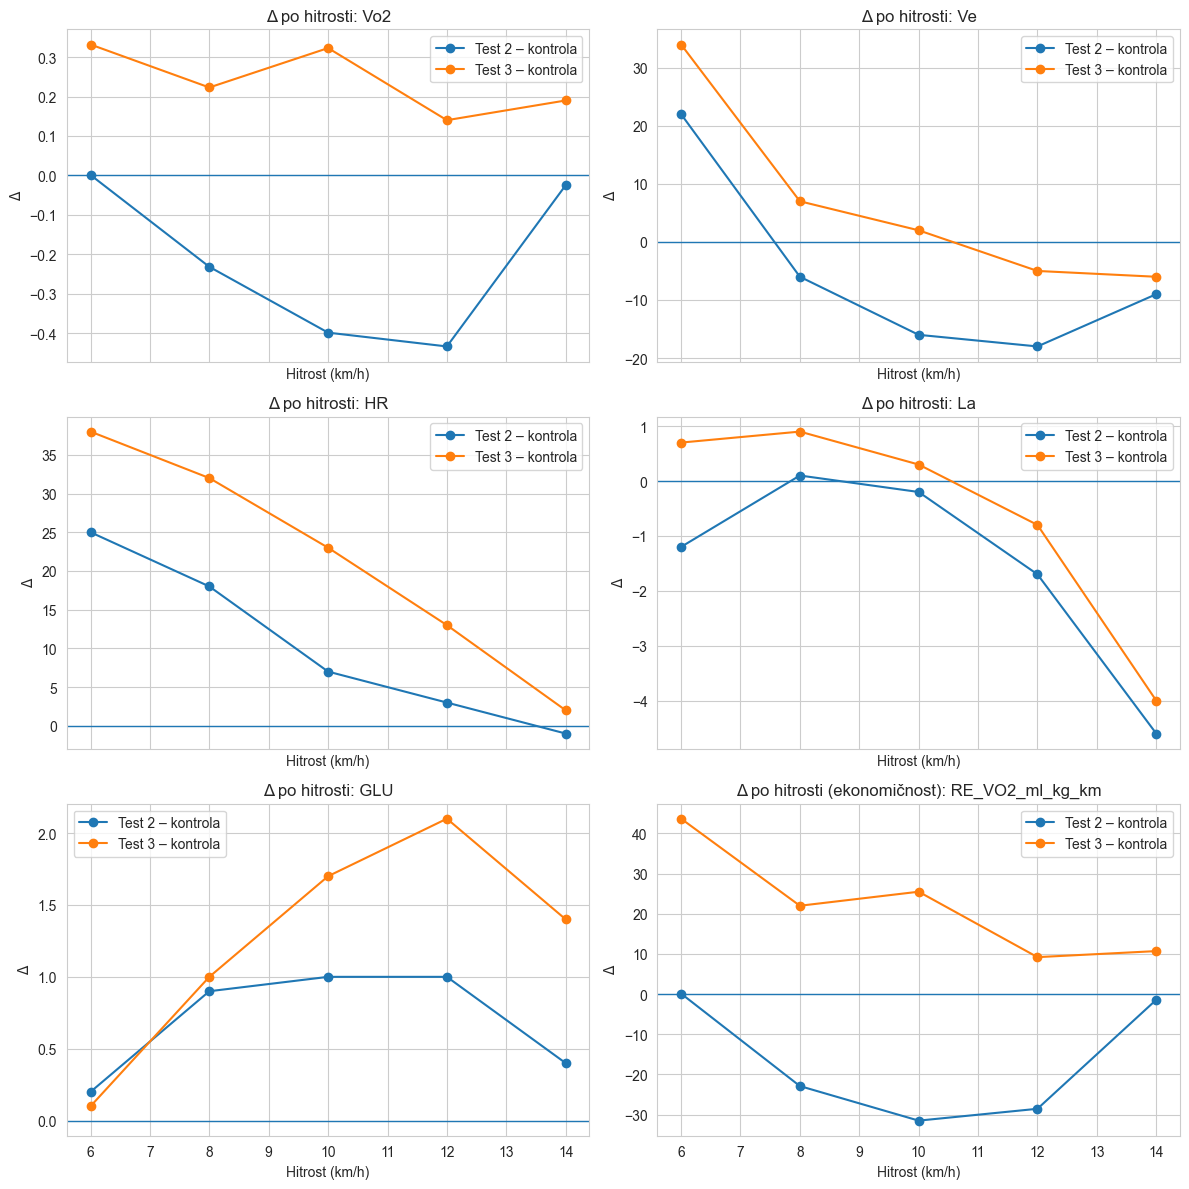

In [22]:
df = gxt_test.copy()

# ekonomičnost
df["RE_VO2_ml_kg_km"] = (df["Vo2"] * 1000 / mass_kg) / df["V"] * 60
df["VE_L_km"] = (df["Ve"] / df["V"]) * 60

vars_to_plot = ["Vo2", "Ve", "HR", "La", "GLU", "RE_VO2_ml_kg_km"] # če želiš
vars_extra = []  # ekonomičnost/ventilacijska cena

# wide tabela (index=V, columns=test)
wide = df.pivot(index="V", columns="test", values=vars_to_plot + vars_extra).sort_index()

delta2 = wide.xs(2, level=1, axis=1) - wide.xs(1, level=1, axis=1)  # test2 - kontrola
delta3 = wide.xs(3, level=1, axis=1) - wide.xs(1, level=1, axis=1)  # test3 - kontrola

def plot_deltas(delta2, delta3, title_prefix=[]):
    variables = delta2.columns.tolist()
    n = len(variables)
    ncols = 2
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4*nrows), sharex=True)
    axes = np.array(axes).reshape(-1)

    V = delta2.index.values

    for i, var in enumerate(variables):
        ax = axes[i]
        ax.axhline(0, linewidth=1)
        ax.plot(V, delta2[var].values, marker="o", label="Test 2 – kontrola")
        ax.plot(V, delta3[var].values, marker="o", label="Test 3 – kontrola")
        ax.set_title(f"{title_prefix[i]}: {var}")
        ax.set_xlabel("Hitrost (km/h)")
        ax.set_ylabel("Δ")

        ax.legend()

    # skrij morebitne prazne osi
    for j in range(i+1, len(axes)):
        axes[j].axis("off")

    fig.tight_layout()
    return fig
t_prefixes = ["Δ po hitrosti", "Δ po hitrosti", "Δ po hitrosti",
              "Δ po hitrosti", "Δ po hitrosti", "Δ po hitrosti (ekonomičnost)"]
fig1 = plot_deltas(delta2[vars_to_plot], delta3[vars_to_plot], title_prefix=t_prefixes)
plt.show()

#fig2 = plot_deltas(delta2[vars_extra], delta3[vars_extra], title_prefix="Δ po hitrosti (ekonomičnost)")
#plt.show()

**Komentar:**
Primerjali smo odziv ene osebe (moški, 40 let, 76 kg) na tri večstopenjske teste do utrujenosti (4-min stopnje): kontrola, test po 60 min enakomernega teka pri intenzivnosti LT1 in test po 40 min enakomernega teka pri intenzivnosti okoli LT2. Analiza je namenjena opisni primerjavi znotraj posameznika. Zaradi odsotnosti ponovitev pogojev in randomizacije vrstnega reda rezultatov ne posplošujemo na populacijo. Primerjavo smo izvedli kot razliko odzivov pri istih hitrostih (Δ po hitrosti). Po predobremenitvi pri LT1 je bil laktat skozi stopnje praviloma nižji kot v kontroli, ob tem pa je bil srčni utrip pri isti hitrosti večji, kar je skladno s spremenjenimi sistemskimi pogoji na dan merjenja. Boljša ekonomičnost po predobremenitvi pri LT1 je skladna z učinkom ogrevanja, možen pa je tudi prispevek akutne biomehanske optimizacije. Ker ne vemo ali so bili okoljski pogoji popolnoma standardizirani, rezultata ne moremo ločiti od dnevne variabilnosti ali merilnega šuma. Po predobremenitvi okoli LT2 je bil srčni utrip pri istih hitrostih izraziteje povišan, VO₂ pa pri večini submaksimalnih hitrosti višji kot v kontroli, kar je skladno z zmanjšano ekonomičnostjo teka po zahtevnejši predobremenitvi. Ker nimamo ocene tipične dnevne variabilnosti iz ponovitev, ne moremo zanesljivo ločiti učinka predobremenitve od dnevnih vplivov (npr. hidracija, temperatura, motivacija, merilni šum), zato rezultate interpretiramo kot hipoteze za nadaljnje ponovitve.